# 09 · News sentiment (the LLM half of the hybrid agent)
**CRISP-DM Phase 2-5 for a new data source** · added 2026-11-23 on the `hybrid-version` branch

| # | Step | Question |
|---|---|---|
| 1 | Data | Where do the headlines come from, how many per day, how complete is the history? |
| 2 | Scoring | How are headlines turned into one score per day (LLM and lexicon)? |
| 3 | Agreement | Do the two scorers see the same news? |
| 4 | Predictive value | Does a day's news tell us anything about the next day's return or volatility? |
| 5 | Look-ahead check | Could the LLM be "remembering" the future instead of reading the news? |
| 6 | Verdict | What the news analyst is (and is not) allowed to do in the agent |

Code: `src/data/news.py`, `src/agents/news_sentiment.py`, `src/evaluation/news_analysis.py`.
Write-up: `docs/12_news_sentiment.md`.

<!-- beginner-guide -->

## How to read this notebook (beginner guide)

| Word | Meaning here |
|---|---|
| **Headline** | The title of one news story that mentions Bitcoin |
| **Sentiment score** | A number from −1 (clearly bad news for the price) to +1 (clearly good news) for one day |
| **LLM scorer** | An open-weights language model (NVIDIA Nemotron 3 Ultra, free on OpenRouter) that reads the day's headlines and gives the score |
| **Lexicon scorer** | A word list: "rally", "approval" count as positive, "hack", "ban" as negative. Simple, transparent, and it cannot know the future |
| **Spearman ρ** | Rank correlation from −1 to +1. 0 = no relation. It ignores extreme outliers, which BTC has many of |
| **Granger test** | Asks: does yesterday's news help predict today's return *beyond* what yesterday's return already tells us? |
| **Event study** | Look at what happened in the 5 days after the most bullish and most bearish news days |
| **Look-ahead bias** | Using information that was not available at the time. An LLM trained on 2025 data "knows" what Bitcoin did in 2024 |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import warnings
warnings.filterwarnings("ignore")

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.agents.news_sentiment import DEFAULT_MODEL, load_sentiment
from src.data.news import coverage, load_headlines
from src.evaluation import news_analysis as na
from src.evaluation.agent_backtest import price_frames
from src.visualization.style import BLUE, NEUTRAL, ORANGE, apply_style, save

apply_style()
heads = load_headlines()
scores = {name: load_sentiment(name) for name in ("lexicon", "llm")}
scores = {k: v for k, v in scores.items() if len(v)}
daily_close = price_frames()["1D"]["close"]
START, END = heads["day"].min(), heads["day"].max()
print(f"{len(heads):,} headlines from '{heads['source'].iloc[0]}', {heads['day'].nunique():,} days, "
      f"{START:%Y-%m-%d} -> {END:%Y-%m-%d}")
print("scorers available:", {k: len(v) for k, v in scores.items()})

3,642 headlines from 'hn', 1,395 days, 2022-01-01 -> 2026-09-30
scorers available: {'lexicon': 1395, 'llm': 1395}


## 1 · Data: source, volume and coverage

Two free sources with full history were wired in (`src/data/news.py`):

* **GDELT DOC 2.0** — up to 75 articles per day from thousands of news sites. The richer source, but it blocks
  clients for long periods after a burst of requests.
* **Hacker News search** (Algolia) — stories whose title mentions Bitcoin, ranked by points. Fewer per day and
  tech-leaning, but reliable.

A snapshot always uses **one** source for the whole history, so the mix of outlets does not change halfway through
and create a fake regime change. Each headline belongs to the UTC day it was published, and the agent may only use a
day's news from the next midnight on.

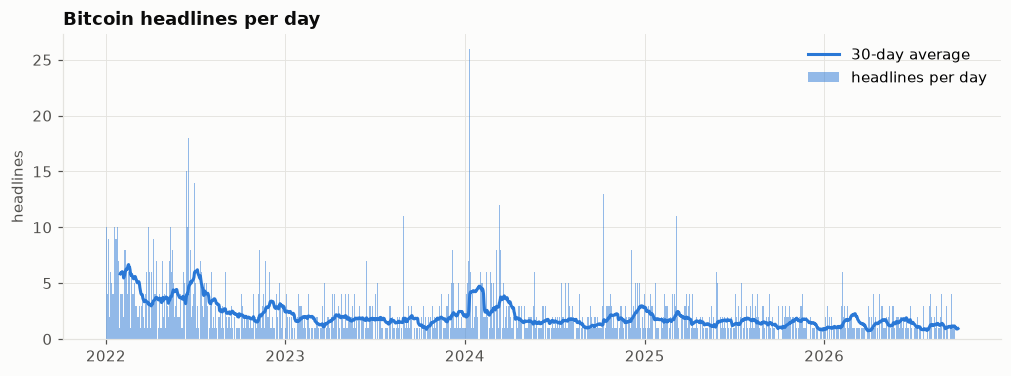

,value
days in range,1734
days with >= 1 headline,1395
share of days covered,80.4%
median headlines per day,2.0
days with >= 5 headlines,10.3%


In [3]:
cov = coverage(heads, f"{START:%Y-%m-%d}", f"{END:%Y-%m-%d}")
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(cov.index, cov["headlines"], width=1.0, color=BLUE, alpha=0.5, label="headlines per day")
ax.plot(cov["headlines"].rolling(30).mean(), color=BLUE, lw=2, label="30-day average")
ax.set_title("Bitcoin headlines per day"); ax.set_ylabel("headlines"); ax.legend(loc="upper right")
save(fig, "09_news_coverage"); plt.show()
summary = pd.Series({
    "days in range": len(cov), "days with >= 1 headline": int((cov["headlines"] > 0).sum()),
    "share of days covered": f"{(cov['headlines'] > 0).mean():.1%}",
    "median headlines per day": float(cov["headlines"].median()),
    "days with >= 5 headlines": f"{(cov['headlines'] >= 5).mean():.1%}",
})
summary.to_frame("value")

In [4]:
# What the input looks like: the top-ranked headlines of a few memorable days.
for day in ("2022-05-10", "2022-11-09", "2024-01-11", "2024-03-14"):
    d = heads[heads["day"] == pd.Timestamp(day, tz="UTC")].sort_values("rank")
    print(f"\n{day}  ({len(d)} headlines)")
    for t in d["title"].head(5):
        print("   -", t)


2022-05-10  (7 headlines)
   - Terra’s stablecoin does its own 2008 crisis: UST crashes, takes Bitcoin with it
   - 40% of Bitcoin investors are now underwater, new data shows
   - MicroStrategy’s Bitcoin Bet on the Verge of Turning Negative
   - Bitcoin Drops Below $30k for the First Time Since July 2021
   - $3.5B bet on Bitcoin becoming a reserve currency for crypto put to test

2022-11-09  (8 headlines)
   - Bitcoin falls under $16,000
   - Russia Is Buying War Supplies Using Bitcoin
   - Panic Among Bitcoin Investors Intensifies: When Will It End?
   - Bitcoin price dips under $17.6K June low as FTX nerves liquidate nearly $1B
   - Bitcoin Reaches $17,229

2024-01-11  (20 headlines)
   - Investment Giant Vanguard Blocks Clients from Buying Bitcoin ETFs
   - Some Bitcoin: Oh, and You've Been Served
   - Bitcoin ETFs Approved by SEC
   - Vanguard Not Allowing Bitcoin ETFs
   - BlackRock, Fidelity early winners in Bitcoin ETF

2024-03-14  (8 headlines)
   - Bitcoin Creator Isn't Cra

## 2 · Scoring: one number per day

* **LLM** (`LLMScorer`, model `nvidia/nemotron-3-ultra-550b-a55b:free`). Open weights from NVIDIA, so anyone can rerun
  it locally; free on OpenRouter. 14 days per request, top 20 headlines per day, temperature 0. The prompt never
  shows a date: days are labelled "Day 1..7", and the model is told to judge the wording only.
* **Lexicon** (`LexiconScorer`). About 110 weighted words with a simple negation rule. It is the control: whatever
  edge it finds cannot come from knowledge of the future.

Both are cached per day in `data/external/news_sentiment_<scorer>.parquet`, so the backtest never calls the API.

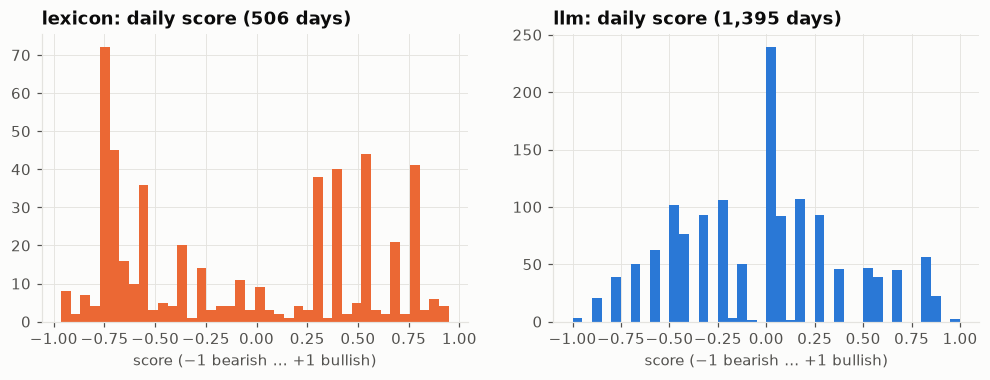

,lexicon,llm
count,506.000,1395.000
mean,-0.089,-0.028
std,0.589,0.437
min,-0.964,-1.000
25%,-0.716,-0.400
50%,-0.174,0.000
75%,0.497,0.275
max,0.947,1.000


In [5]:
fig, axes = plt.subplots(1, len(scores), figsize=(5.5 * len(scores), 3.4), squeeze=False)
for ax, (name, s) in zip(axes[0], scores.items()):
    x = s.loc[s["confidence"] > 0, "score"]
    ax.hist(x, bins=40, color=BLUE if name == "llm" else ORANGE)
    ax.set_title(f"{name}: daily score ({len(x):,} days)"); ax.set_xlabel("score (−1 bearish … +1 bullish)")
save(fig, "09_score_distribution"); plt.show()
pd.DataFrame({n: s.loc[s["confidence"] > 0, "score"].describe() for n, s in scores.items()}).round(3)

## 3 · Do the two scorers agree?

In [6]:
if {"llm", "lexicon"} <= set(scores):
    agree = na.scorer_agreement(scores["llm"], scores["lexicon"])
    display(pd.Series(agree).to_frame("LLM vs lexicon"))
else:
    print("LLM scores not available yet: run `python -m src.agents.news_sentiment --scorer llm` "
          "(needs OPENROUTER_API_KEY in .env). The rest of the notebook uses the lexicon.")

,LLM vs lexicon
days,1.395000e+03
spearman_rho,3.865399e-01
p_value,6.166215e-51
sign_agreement,7.688985e-01


## 4 · Predictive value

The score of day D is compared with the return of day **D+1**. The same-day correlation is shown as well: news
that only *describes* the move that already happened is not a forecast.

In [7]:
tables = {}
for name, s in scores.items():
    a = na.align(s, daily_close)
    corr = na.correlations(a).assign(scorer=name)
    gr = na.granger(a).assign(scorer=name)
    ev = na.event_study(a).assign(scorer=name)
    tables[name] = (a, corr, gr, ev)
pd.concat([t[1] for t in tables.values()]).set_index(["scorer", "compared with"]).round(4)

spearman_rho  p_value  days
scorer  compared with                             
lexicon same_ret             0.0741   0.0964   505
        next_ret            -0.0487   0.2743   505
        next_abs_ret        -0.0194   0.6641   505
        next_5d_ret         -0.0601   0.1773   505
llm     same_ret             0.0690   0.0100  1394
        next_ret            -0.0135   0.6155  1394
        next_abs_ret        -0.0061   0.8209  1394
        next_5d_ret         -0.0009   0.9722  1392

In [8]:
pd.concat([t[2] for t in tables.values()]).set_index(["scorer", "direction", "lag_days"]).round(4)

f_stat  p_value
scorer  direction         lag_days                  
lexicon score -> same_ret 1          2.6434   0.1046
                          2          1.2580   0.2851
                          3          0.9320   0.4250
        same_ret -> score 1          3.4381   0.0643
                          2          2.4960   0.0834
                          3          2.0256   0.1094
llm     score -> same_ret 1          0.1826   0.6692
                          2          0.3927   0.6753
                          3          1.2841   0.2783
        same_ret -> score 1         32.3040   0.0000
                          2         24.9295   0.0000
                          3         17.8452   0.0000

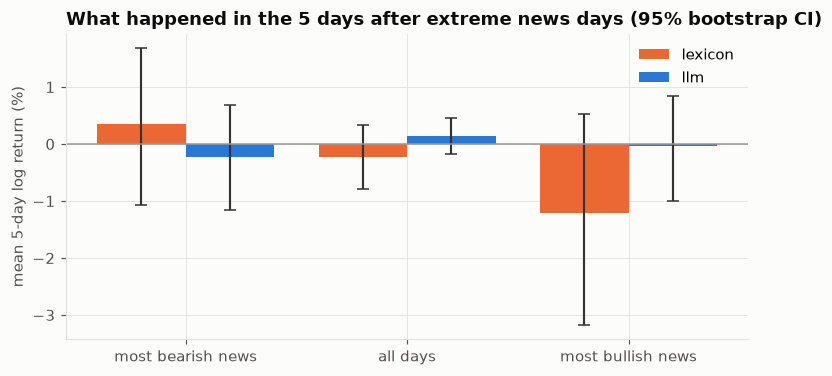

days  mean_5d_return  ci_low  ci_high  hit_rate_up
scorer  group                                                                
lexicon most bullish news    54         -0.0121 -0.0318   0.0053       0.5000
        most bearish news    87          0.0035 -0.0108   0.0168       0.5632
        all days            505         -0.0022 -0.0079   0.0034       0.5228
llm     most bullish news   164         -0.0004 -0.0100   0.0084       0.4817
        most bearish news   175         -0.0023 -0.0115   0.0069       0.5200
        all days           1392          0.0013 -0.0018   0.0045       0.5180

In [9]:
ev_all = pd.concat([t[3] for t in tables.values()])
fig, ax = plt.subplots(figsize=(8, 3.6))
groups = ["most bearish news", "all days", "most bullish news"]
width = 0.8 / len(tables)
for i, (name, (_, _, _, ev)) in enumerate(tables.items()):
    e = ev.set_index("group").loc[groups]
    x = np.arange(len(groups)) + i * width
    ax.bar(x, e["mean_5d_return"] * 100, width, label=name, color=BLUE if name == "llm" else ORANGE)
    ax.errorbar(x, e["mean_5d_return"] * 100, yerr=[(e["mean_5d_return"] - e["ci_low"]) * 100,
                (e["ci_high"] - e["mean_5d_return"]) * 100], fmt="none", ecolor="#333", capsize=4)
ax.set_xticks(np.arange(len(groups)) + width * (len(tables) - 1) / 2, groups)
ax.axhline(0, color=NEUTRAL, lw=1); ax.set_ylabel("mean 5-day log return (%)")
ax.set_title("What happened in the 5 days after extreme news days (95% bootstrap CI)"); ax.legend()
save(fig, "09_event_study"); plt.show()
ev_all.set_index(["scorer", "group"]).round(4)

## 5 · Look-ahead check

The LLM was trained on web text that ends somewhere in 2025, which overlaps most of this history. If it scored
headlines using memory of later prices, its scores would predict returns much better **before** its training cutoff
than after it, and much better than the lexicon. The split below uses 2025-01-01 as an approximate cutoff.

In [10]:
rows = []
CUTOFF = pd.Timestamp("2025-01-01", tz="UTC")
for name, (a, *_rest) in tables.items():
    for label, part in (("before 2025", a[a.index < CUTOFF]), ("2025 and later", a[a.index >= CUTOFF])):
        c = na.correlations(part).set_index("compared with").loc["next_ret"]
        rows.append({"scorer": name, "period": label, "days": int(c["days"]),
                     "rho with next-day return": c["spearman_rho"], "p_value": c["p_value"]})
pd.DataFrame(rows).set_index(["scorer", "period"]).round(4)

days  rho with next-day return  p_value
scorer  period                                                 
lexicon before 2025      371                   -0.0987   0.0576
        2025 and later   134                    0.0802   0.3572
llm     before 2025      942                   -0.0117   0.7188
        2025 and later   452                   -0.0175   0.7113

## 6 · Verdict

* **The LLM reads the news well:** it rates every day, agrees with the lexicon's direction on 77% of days, and its
  reasons name the right events (ETF filings, exchange failures, regulation).
* **But the news has no predictive value.** LLM score vs the next-day return: ρ = −0.01 (p = 0.62); vs its size:
  p = 0.82; the 5 days after the most bullish / bearish days are not different from an average day.
* **News follows price.** Same-day ρ = +0.07 (p = 0.01) and Granger *return → score* p < 0.0001, while
  *score → return* p > 0.25. Public headlines describe moves that have already happened.
* **No sign of look-ahead:** the LLM's next-day correlation is ≈ 0 both before and after 2025.
* **Consequence for the agent:** the news analyst stays weak by design; `hybrid_llm` ranked last of four teams on the
  development period for 4h and 1D and was not selected (`docs/13`). Its value is explaining in words what the agent
  saw on a given day.

Write-up: `docs/12_news_sentiment.md`.